# 06 · Covariance forecasts as hedging decisions

**RQ3:** Does a covariance estimate support a useful economic decision?
Keep one near contract and use the middle/far contracts as hedges. The objective
is reduced settlement risk, not an expected-return or trading-alpha strategy.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(rows, columns):
    print(" | ".join(columns))
    for row in rows:
        print(
            " | ".join(
                (
                    f"{row.get(c):.6g}" if isinstance(row.get(c), float) else str(row.get(c))
                    for c in columns
                )
            )
        )

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Decision problem and chronology

Given the issued PSD raw contract covariance $\widehat K_n$, solve

$$
\min_{h\in[-2,2]^2}(1,h^\top)\widehat K_n(1,h^\top)^\top.
$$

The solver checks the unconstrained stationary point, edges and corners, so
singular PSD controls remain well-defined. It receives no future price. Each
rule selects its risk-model settings on 2023 validation QLIKE, then issues
positions using data through the origin. The same actual contracts are held
until next session. These are risk-selected policies, not separately
hedging-loss-tuned policies.

In [2]:
joint = evidence["joint"]
print(joint["hedge_scope"])
print("Bounds:", joint["joint_config"]["hedge_bounds"])
table(
    joint["hedge_summary"],
    [
        "method",
        "common_count",
        "realized_rms_cny",
        "reduction_vs_unhedged",
        "predicted_rms_cny",
        "realized_over_predicted_second_moment",
    ],
)

one near contract plus two bounded maturity-target positions, settlement P&L; turnover is a position-change proxy and excludes execution/roll costs
Bounds: [-2.0, 2.0]
method | common_count | realized_rms_cny | reduction_vs_unhedged | predicted_rms_cny | realized_over_predicted_second_moment
unhedged | 484 | 3487.1 | 0 | None | None
direct | 484 | 501.431 | 0.979323 | 664.666 | 0.569134
direct_calendar | 484 | 501.431 | 0.979323 | 664.666 | 0.569134
direct_session | 484 | 507.925 | 0.978784 | 595.519 | 0.727458
factor | 484 | 684.946 | 0.961418 | 303.202 | 5.10326
factor_calendar | 484 | 684.946 | 0.961418 | 303.202 | 5.10326
factor_session | 484 | 685.335 | 0.961374 | 270.884 | 6.4009
joint | 484 | 533 | 0.976637 | 666.489 | 0.639542
joint_calendar | 484 | 533 | 0.976637 | 666.489 | 0.639542
joint_raw | 484 | 533 | 0.976637 | 666.489 | 0.639542
joint_session | 484 | 541.284 | 0.975905 | 596.452 | 0.823566
source | 484 | 624.091 | 0.967969 | 312.921 | 3.97765


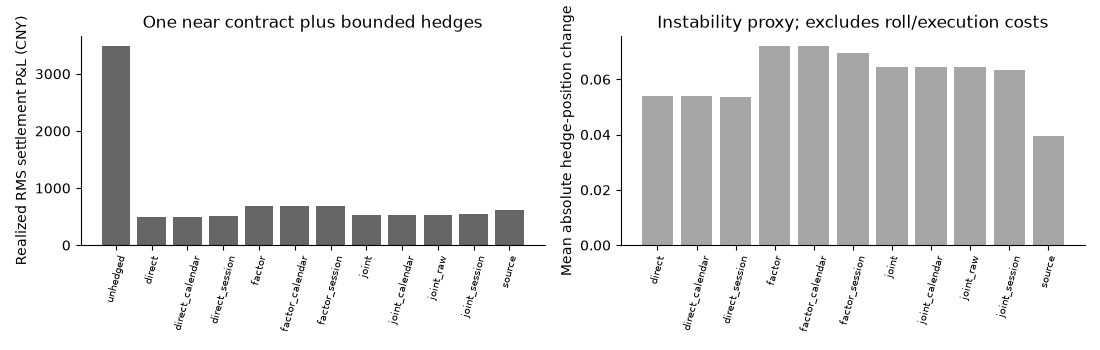

In [3]:
rows = joint["hedge_summary"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(range(len(rows)), [r["realized_rms_cny"] for r in rows], color="0.4")
axes[0].set_xticks(range(len(rows)), [r["method"] for r in rows], rotation=75, fontsize=7)
axes[0].set(
    ylabel="Realized RMS settlement P&L (CNY)", title="One near contract plus bounded hedges"
)
hedged = [r for r in rows if r["method"] != "unhedged"]
axes[1].bar(
    range(len(hedged)), [r["mean_position_change_proxy"] or 0 for r in hedged], color="0.65"
)
axes[1].set_xticks(range(len(hedged)), [r["method"] for r in hedged], rotation=75, fontsize=7)
axes[1].set(
    ylabel="Mean absolute hedge-position change",
    title="Instability proxy; excludes roll/execution costs",
)
fig.tight_layout()
plt.show()

## Paired realized risk and position stability

All displayed rules use the common scored-origin cohort. Negative paired
squared-P&L differences favor the listed rule. Bootstrap blocks resample
paired sessions, not independent strategies. Mean hedge positions and bound
hits help detect unstable optimization even when average risk is small.

In [4]:
table(
    joint["hedge_paired"],
    ["method", "reference", "count", "mean", "bootstrap_standard_error", "bootstrap_percentile_95"],
)
table(
    [r for r in joint["hedge_summary"] if r["method"] != "unhedged"],
    ["method", "mean_hedge_positions", "bound_hit_fraction", "mean_position_change_proxy"],
)
print(json.dumps(joint["availability"], indent=2))

method | reference | count | mean | bootstrap_standard_error | bootstrap_percentile_95
direct | unhedged | 484 | -1.19084e+07 | 2.24024e+06 | [-16332758.21662859, -7701864.4431870105]
direct_calendar | unhedged | 484 | -1.19084e+07 | 2.24024e+06 | [-16332758.21662859, -7701864.4431870105]
direct_calendar | direct | 484 | 0 | 0 | [0.0, 0.0]
direct_session | unhedged | 484 | -1.19019e+07 | 2.23787e+06 | [-16320954.473925041, -7702042.553238468]
direct_session | direct | 484 | 6554.69 | 8336.07 | [-6393.943523641995, 24610.785562411267]
factor | unhedged | 484 | -1.16907e+07 | 2.19771e+06 | [-16045311.590758435, -7569910.058831353]
factor | direct | 484 | 217718 | 83130.7 | [83309.11816469523, 398474.22926803364]
factor_calendar | unhedged | 484 | -1.16907e+07 | 2.19771e+06 | [-16045311.590758435, -7569910.058831353]
factor_calendar | direct | 484 | 217718 | 83130.7 | [83309.11816469523, 398474.22926803364]
factor_session | unhedged | 484 | -1.16902e+07 | 2.19665e+06 | [-16029151.93127444

## Interpretation and next decision

Realized RMS is CNY 3,487 unhedged, 501 with direct covariance, 533 with joint
factor/residual, 624 with the original source model and 685 with factor-only.
Joint minus direct squared P&L averages +32,657 CNY², with descriptive bootstrap
range [17,545, 47,609]; direct has lower realized risk in this sample.

This closes the pipeline from data and curve reconstruction to model risk and
a constrained decision. It does not establish an executable backtest: contract
switching, actual fills, margin, roll mechanics, transaction costs and liquidity
capacity are not modeled. A later execution-aware study needs these inputs and
an uninspected evaluation period. Do not turn lower settlement RMS alone into
a profitability or CV performance claim.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/06_hedging_decisions.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).